# Cue accumulation with BPTT

The network (50 LIF + 50 ALIF neurons, 2 readouts) is trained with BPTT on cross-entropy during the decision period with a firing-rate regularization towards 10 Hz.

Training follows a curriculum of 1 -> 3 -> 5 -> 7 cues. Every 10 iterations the error is measured on a new batch, and when it is confirmed on 8 more batches the next number of cues is used.

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from snnrl.network import Weights, init_weights, make_network_params
from snnrl.neuron import make_params
from snnrl.supervised import make_evaluate, run_batch, train_cue_accumulation
from snnrl.tasks import CueAccumulation, sample_batch

In [2]:
N_LIF = 50
N_ALIF = 50
N_OUT = 2
TARGET_RATE = 10.0 # Hz
TEST_BATCH_SIZE = 64
CURRICULUM = (1,3,5,7)
VALIDATE_EVERY = 10

RETRAIN = False # Load previously trained weights from results/
SEED = 0

path = Path("results") / "04_bptt.npz"

main_key = jax.random.key(SEED)

In [3]:
task = CueAccumulation()
params = make_network_params(make_params(n_lif=N_LIF, n_alif=N_ALIF))
T = task.trial_length

## 1. Training

In [4]:
main_key, init_key = jax.random.split(main_key)

if RETRAIN or not path.exists():
    # 1. Initialize weights
    weights0 = init_weights(init_key, task.n_in, N_OUT, params)
    t_start = time.time()
    # 2. Train weights
    weights, history = train_cue_accumulation(
        main_key,
        weights0,
        params,
        task,
        curriculum=CURRICULUM,
        validate_every=VALIDATE_EVERY,
        stop_at_last_stage=False
    )
    print(f"trained {len(history)} iterations in {time.time() - t_start:.0f} s")
    # 3. Save weights and training history
    path.parent.mkdir(exist_ok=True)
    np.savez(path,
             **{f"w_{k}": np.asarray(v) for k, v in vars(weights).items()},
             **{f"history_{k}": np.array([r.get(k, np.nan) for r in history], dtype=float)
                for k in sorted(set().union(*history))})

saved = np.load(path)
weights = Weights(**{k[2:]: jnp.asarray(saved[k]) for k in saved.files if k.startswith("w_")})
history = {k[8:]: saved[k] for k in saved.files if k.startswith("history_")}
it, n_cues = history["iteration"].astype(int), history["n_cues"].astype(int)
print(f"{len(it)} iterations; 7 cues reached at iteration {it[n_cues == 7][0]}")

2000 iterations; 7 cues reached at iteration 131


## 2. Results

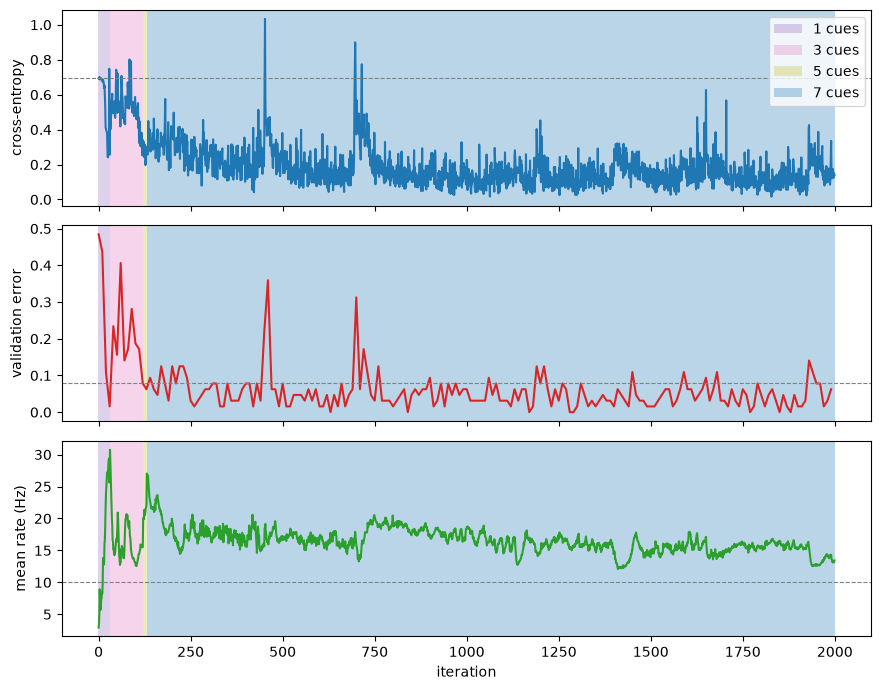

In [5]:
ce = history["cross_entropy"]
rate = history["rate"]
validated = ~np.isnan(history["val_error"])
val_it, val_err = it[validated], history["val_error"][validated]

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
# Cross-entropy
axes[0].plot(it, ce, color="C0")
axes[0].axhline(np.log(2), color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("cross-entropy")
# Validation error
axes[1].plot(val_it, val_err, color="C3")
axes[1].axhline(0.08, color="gray", ls="--", lw=0.8)
axes[1].set_ylabel("validation error")
# Mean rate
axes[2].plot(it, rate, color="C2")
axes[2].axhline(TARGET_RATE, color="gray", ls="--", lw=0.8)
axes[2].set_ylabel("mean rate (Hz)")
axes[2].set_xlabel("iteration")

for ax in axes:
    for n in CURRICULUM:
        stage = it[n_cues == n]
        ax.axvspan(
            stage[0] - 0.5, stage[-1] + 0.5, 
            color=f"C{n+3}", alpha=0.3, lw=0, label=f"{n} cues"
        )
axes[0].legend()
plt.tight_layout()

## 3. Test

In [6]:
N_BATCH = 32

evaluate = make_evaluate(
    params, 
    task, 
    batch_size=TEST_BATCH_SIZE,
    c_reg=1.0,
    rate_target=TARGET_RATE
)

main_key, test_key = jax.random.split(main_key)

metrics = [evaluate(weights, key, 7) for key in jax.random.split(test_key, N_BATCH)]
accuracies = [m["accuracy"] for m in metrics]
errors = [1 - a for a in accuracies]
mean_error = np.mean(errors)
se_error = np.sqrt(mean_error * (1 - mean_error) / (N_BATCH*TEST_BATCH_SIZE))

print(f"Test error on 2048 trials with 7 cues: {mean_error:.3f} ± {se_error:.3f}")

Test error on 2048 trials with 7 cues: 0.039 ± 0.004


Example trial

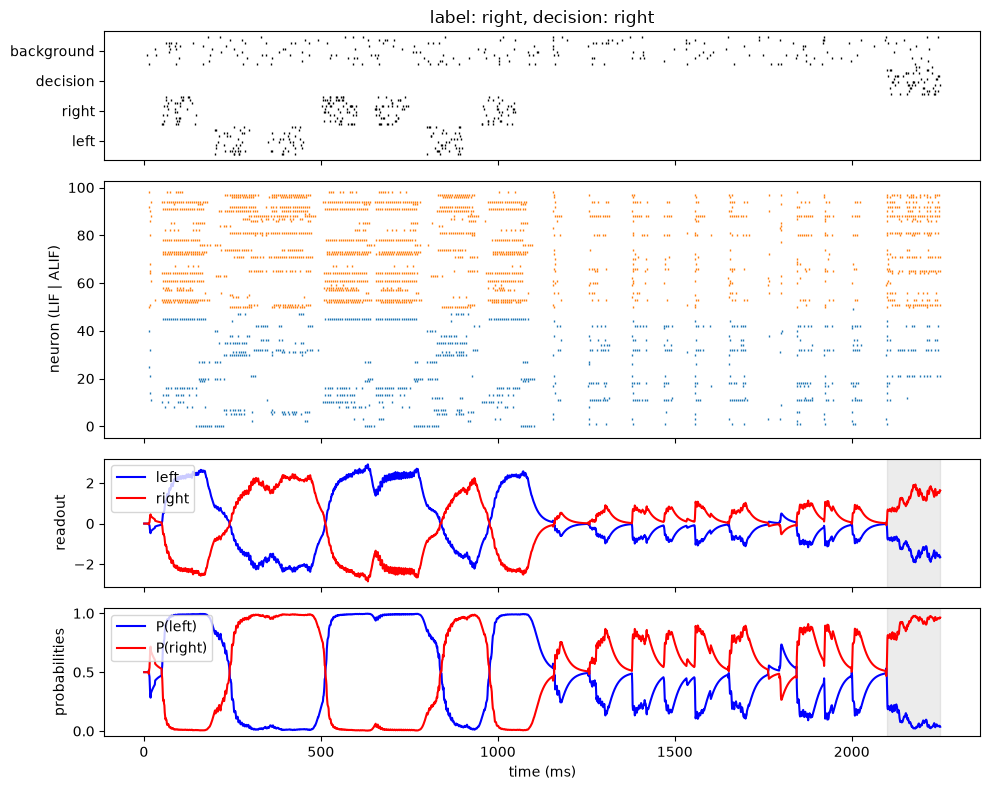

In [7]:
main_key, sample_key = jax.random.split(main_key)

populations = ["left", "right", "decision", "background"]

x, label = sample_batch(sample_key, batch_size=1, n_cues=7, task=task)
label = 'right' if label[0] else 'left'
_, states, y = run_batch(x, weights, params)
z = states.neuron.z[0]
y = y[0]
p = jax.nn.softmax(y, axis=-1)
decision = 'right' if p[-task.t_decision:].mean(0).argmax() == 1 else 'left'
t = np.arange(1, T + 1)


fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [1, 2, 1, 1]})

# Plot input spikes
times, inputs = jnp.nonzero(x[0])
axes[0].plot(times + 1, inputs, "|", color="k", ms=2)
axes[0].set_yticks([4.5, 14.5, 24.5, 34.5], populations)
axes[0].set_title(f"label: {label}, decision: {decision}")
# Plot neuron spikes
times, neurons = jnp.nonzero(z)
is_alif = params.neuron.is_alif[neurons]
axes[1].plot(times[~is_alif] + 1, neurons[~is_alif], "|", color="C0", ms=2)
axes[1].plot(times[is_alif] + 1, neurons[is_alif], "|", color="C1", ms=2)
axes[1].set_ylabel("neuron (LIF | ALIF)")
# Plot readout activity
axes[2].plot(t, y[:, 0], label="left", color="b")
axes[2].plot(t, y[:, 1], label="right", color="r")
axes[2].axvspan(T - task.t_decision, T, color="gray", alpha=0.15)
axes[2].legend(loc="upper left")
axes[2].set_ylabel("readout")
# Plot readout probabilities
axes[3].plot(t, p[:, 0], label="P(left)", color="b")
axes[3].plot(t, p[:, 1], label="P(right)", color="r")
axes[3].axvspan(T - task.t_decision, T, color="gray", alpha=0.15)
axes[3].set_ylabel("probabilities")
axes[3].set_xlabel("time (ms)")
axes[3].legend(loc="upper left")

plt.tight_layout()